In [12]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sklearn as sk

## Q1. Load CIFAR dataset

In [13]:
# Load CIFAR-10 from the provided local batches directory
data_dir = "cifar-10-batches-py"

def _unpickle(file_path):
    with open(file_path, "rb") as f:
        return pickle.load(f, encoding="bytes")

# Training set (5 data batches)
train_data = []
train_labels = []
for i in range(1, 6):
    batch = _unpickle(os.path.join(data_dir, f"data_batch_{i}"))
    train_data.append(batch[b"data"] )
    train_labels.extend(batch[b"labels"] )

X = np.vstack(train_data)
Y = np.array(train_labels)

## Q2. Select 3 Classes and display cases

In [14]:
# Viewing the unique labels in the dataset
Y_set = set(Y)
Y_set

{np.int64(0),
 np.int64(1),
 np.int64(2),
 np.int64(3),
 np.int64(4),
 np.int64(5),
 np.int64(6),
 np.int64(7),
 np.int64(8),
 np.int64(9)}

In [ ]:
# Selecting 3 classes from the dataset
Y_classes = [3, 6, 9]
class_indices = {label: np.where(Y == label)[0] for label in Y_classes}

# Filter X and Y to only include samples from the selected classes
X = np.array([X[i] for i in range(len(X)) if Y[i] in Y_classes])
Y = np.array([Y[i] for i in range(len(Y)) if Y[i] in Y_classes])

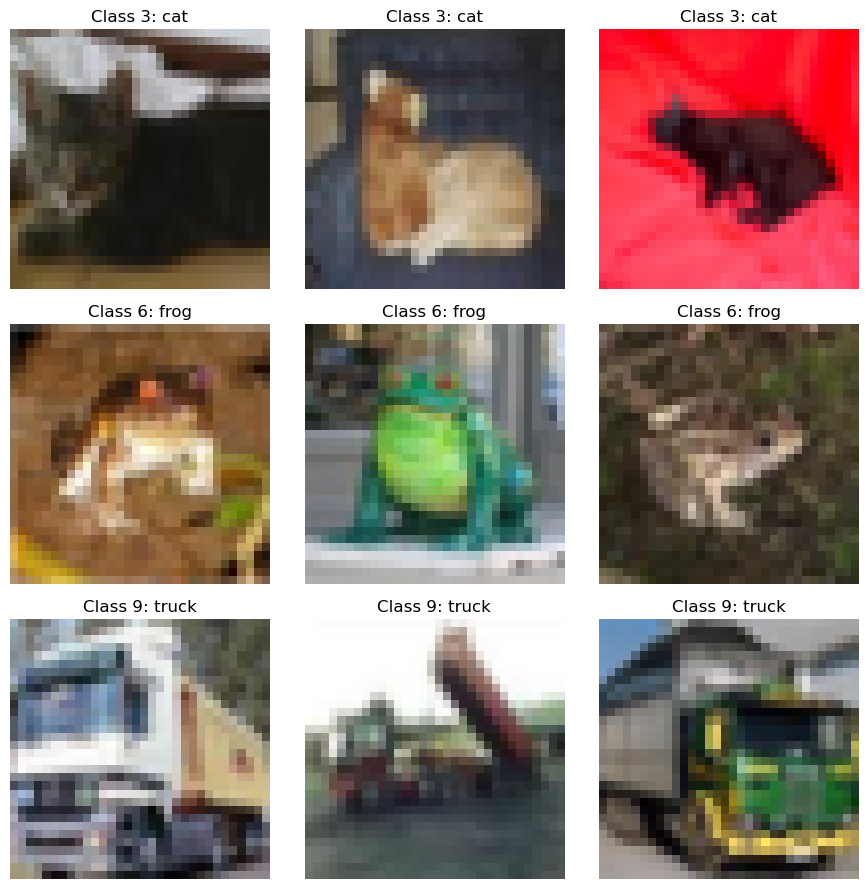

In [16]:
# Display 3 images for each selected class
class_names = {
    3: "cat",
    6: "frog", 
    9: "truck"
}

images_per_class = 3
fig, axes = plt.subplots(len(Y_classes), images_per_class, figsize=(9, 3 * len(Y_classes)))

if len(Y_classes) == 1:
    axes = np.array([axes])

for row, label in enumerate(Y_classes):
    idx = np.where(Y == label)[0][:images_per_class]

    for col in range(images_per_class):
        ax = axes[row, col]
        img = X[idx[col]].reshape(3, 32, 32).transpose(1, 2, 0)
        ax.imshow(img.astype(np.uint8))
        ax.axis("off")
        ax.set_title(f"Class {label}: {class_names.get(label, str(label))}")

plt.tight_layout()
plt.show()

## Q5 Split classes into training set and testing set and develop random tree

In [ ]:
from sklearn.model_selection import train_test_split

# Split the dataset into its 3 classes
X_CL1 = X[np.where(Y == Y_classes[0])[0]]
X_CL2 = X[np.where(Y == Y_classes[1])[0]]
X_CL3 = X[np.where(Y == Y_classes[2])[0]]
class_data = [X_CL1, X_CL2, X_CL3]

Y_CL1 = Y[np.where(Y == Y_classes[0])[0]]
Y_CL2 = Y[np.where(Y == Y_classes[1])[0]]
Y_CL3 = Y[np.where(Y == Y_classes[2])[0]]
class_labels = [Y_CL1, Y_CL2, Y_CL3]

# Split each class into training and testing sets (85% train, 15% test)
X_train = []
X_test = []
Y_train = []
Y_test = []

for i in range(3):
    train_data, test_data, train_labels, test_labels = train_test_split(class_data[i], class_labels[i], test_size=0.15)
    X_train.append(train_data)
    X_test.append(test_data)
    Y_train.append(train_labels)
    Y_test.append(test_labels)

# Concatenating the training and testing sets for all classes
X_train = np.vstack(X_train)
Y_train = np.hstack(Y_train)
X_test = np.vstack(X_test)
Y_test = np.hstack(Y_test)


In [ ]:
# Implememnt scikit-learn's Random Forest Classifier
import time
from sklearn.ensemble import RandomForestClassifier

# Train a Random Forest with 100 trees and measure training time
model = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42) # Settting n_jobs=-1 greatly reduces training time
start_time = time.time()
RF = model.fit(X_train, Y_train)
end_time = time.time()
print(f"Training time: {end_time - start_time:.2f} seconds")

Training time: 5.56 seconds


In [ ]:
from sklearn.metrics import accuracy_score

# Evaluate the Random Forest on the test and training sets
test_pred = RF.predict(X_test)
test_acc = accuracy_score(Y_test, test_pred)
train_pred = RF.predict(X_train)
train_acc = accuracy_score(Y_train, train_pred)

print(f"Random Forest Test Accuracy: {test_acc:.4f}")
print(f"Random Forest Train Accuracy: {train_acc:.4f}")

Random Forest Test Accuracy: 0.7427
Random Forest Train Accuracy: 1.0000


## Q6 Display Confusion Matrix

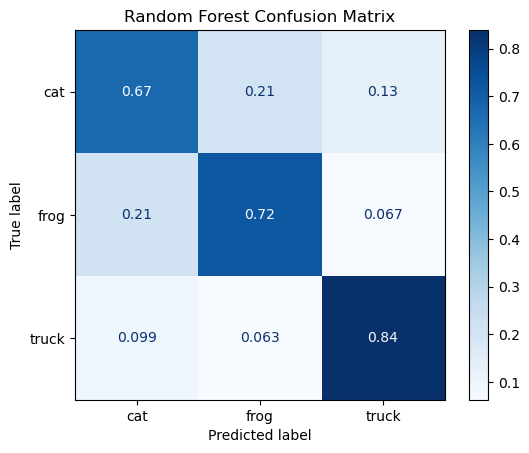

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create and display the confusion matrix
confusion = confusion_matrix(Y_test, test_pred, normalize="true")
ConfusionMatrixDisplay(confusion, display_labels=list(class_names.values())).plot(cmap=plt.cm.Blues)
plt.title("Random Forest Confusion Matrix")
plt.show()

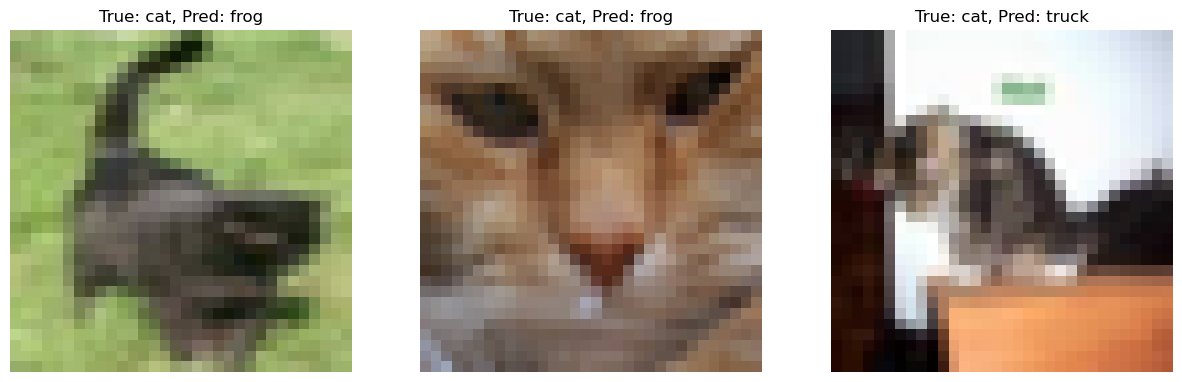

In [ ]:
# Inspect 3 misclassified examples from the test set
misclassified_indices = np.where(test_pred != Y_test)[0][:3] # Get the first 3 misclassified indices

# Display the misclassified examples with their true and predicted labels
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, idx in enumerate(misclassified_indices):
    img = X_test[idx].reshape(3, 32, 32).transpose(1, 2, 0)
    axes[i].imshow(img.astype(np.uint8))
    axes[i].set_title(f"True: {class_names.get(Y_test[idx], str(Y_test[idx]))}, Pred: {class_names.get(test_pred[idx], str(test_pred[idx]))}")
    axes[i].axis("off")
plt.show()

## Q7 Improve RF accuracy by tweaking parameters

In [ ]:
RF.get_params()
# We will adjust the following parameters to see if we can improve the model's performance:
params = {
    "criterion": "gini",
    "max_depth": None,
    "min_samples_split": 2,
    "min_samples_leaf": 1,
    "max_samples": None,
    "max_features": "sqrt",
    "max_leaf_nodes": None,

}
# Varying the parameters one at a time to see their effect on the model's performance
options = {
    "criterion": ["gini", "entropy", "log_loss"],
    "max_depth": [None, 10, 20, 30, 50],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", 20, 50, 100, 150],
    "max_leaf_nodes": [None, 10, 20, 30],
    "max_samples": [None, 0.25, 0.5, 0.75]
}

In [ ]:
times = []

# Iterating through each parameter and its options, training a new model for each option, and evaluating its performance
for param in params:
    accuracies = []

    for option in options[param]:
        print(f"Testing {param}: {option}")
        # Create a new model with the current parameter option while keeping other parameters fixed
        model = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
        model.set_params(**{k: v for k, v in params.items() if k != param}, **{param: option}) 

        start_time = time.time()
        RF = model.fit(X_train, Y_train) # Fit the model with the current parameter option
        end_time = time.time()

        print(f"\t{option} time: {end_time - start_time:.2f} seconds")
        times.append(end_time - start_time)

        test_pred = RF.predict(X_test) # Predict on the test set with the current parameter option
        test_acc = accuracy_score(Y_test, test_pred)

        accuracies.append(test_acc)
        print(f"\t{option} Accuracy: {test_acc:.4f}")
        print("\n")


    print(f"Best {param}: {options[param][np.argmax(accuracies)]} with accuracy: {max(accuracies):.4f}")
    params[param] = options[param][np.argmax(accuracies)] # Updating best parameter based on the highest accuracy
    print(f"Accuracy disparity: {max(accuracies) - min(accuracies):.4f}")
    print("-" * 50)

print(f"Total training time for all parameter combinations: {sum(times)/60:.2f} minutes")

Testing criterion: gini
	gini time: 5.79 seconds
	gini Accuracy: 0.7427


Testing criterion: entropy
	entropy time: 6.54 seconds
	entropy Accuracy: 0.7422


Testing criterion: log_loss
	log_loss time: 6.40 seconds
	log_loss Accuracy: 0.7422


Best criterion: gini with accuracy: 0.7427
Accuracy disparity: 0.0004
--------------------------------------------------
Testing max_depth: None
	None time: 5.82 seconds
	None Accuracy: 0.7427


Testing max_depth: 10
	10 time: 3.40 seconds
	10 Accuracy: 0.7253


Testing max_depth: 20
	20 time: 4.89 seconds
	20 Accuracy: 0.7409


Testing max_depth: 30
	30 time: 5.38 seconds
	30 Accuracy: 0.7369


Testing max_depth: 50
	50 time: 5.85 seconds
	50 Accuracy: 0.7413


Best max_depth: None with accuracy: 0.7427
Accuracy disparity: 0.0173
--------------------------------------------------
Testing min_samples_split: 2
	2 time: 6.19 seconds
	2 Accuracy: 0.7427


Testing min_samples_split: 5
	5 time: 6.39 seconds
	5 Accuracy: 0.7347


Testing min_samples_spl

In [24]:
params

{'criterion': 'gini',
 'max_depth': None,
 'min_samples_split': 10,
 'min_samples_leaf': 1,
 'max_samples': None,
 'max_features': 100,
 'max_leaf_nodes': None}

## Q8. Create $RF_{OOB}$ using the whole dataset

In [ ]:
# Creating an out-of-bag model with the best parameters found
oob_model = RandomForestClassifier(n_estimators=100,
                                   n_jobs=-1,
                                   oob_score=True,
                                   max_features="sqrt",
                                   random_state=42).set_params(**params)
RF_oob = oob_model.fit(X, Y) # Fit the model on the entire dataset to get the OOB score
print(f"OOB Score: {RF_oob.oob_score_:.4f}")

# Train a new Random Forest with the best parameters found and evaluate its performance on the test set
RF_100 = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42).set_params(**params)
RF_100.fit(X_train, Y_train)
test_pred = RF_100.predict(X_test)
test_acc = accuracy_score(Y_test, test_pred)
print(f"Random Forest Test Accuracy with 100 trees: {test_acc:.4f}")

OOB Score: 0.7263
Random Forest Test Accuracy with 100 trees: 0.7516


## Q9. Create RF with bag sizes of {200, 400, 600}

In [77]:
# n_estimator values to test
bags = [100, 200, 400, 600]

# Dictionary to store the trained models for each n_estimator value
forests = {
    "100": None,
    "200": None,
    "400": None,
    "600": None
}

# Dictionary to store respective confusion matrices for each n_estimator value
confusion_matrices = {}

#Dictionary to store accuracies for each n_estimator value
accuracies = {}
for bags in bags:
    # Train a Random Forest with the current n_estimator value and the best parameters found
    model = RandomForestClassifier(n_estimators=bags, n_jobs=-1, random_state=42).set_params(**params)
    forests[str(bags)] = model.fit(X_train, Y_train)

    # Calculate and store the test accuracy for the current model
    test_pred = forests[str(bags)].predict(X_test)
    test_acc = accuracy_score(Y_test, test_pred)
    accuracies[str(bags)] = test_acc

    # Calculate and store the confusion matrix for the current model
    confusion_matrices[str(bags)] = confusion_matrix(Y_test, test_pred, normalize="true")




Random Forest Test Accuracy with 100 trees: 0.7516
Random Forest Test Accuracy with 200 trees: 0.7440
Random Forest Test Accuracy with 400 trees: 0.7516
Random Forest Test Accuracy with 600 trees: 0.7471


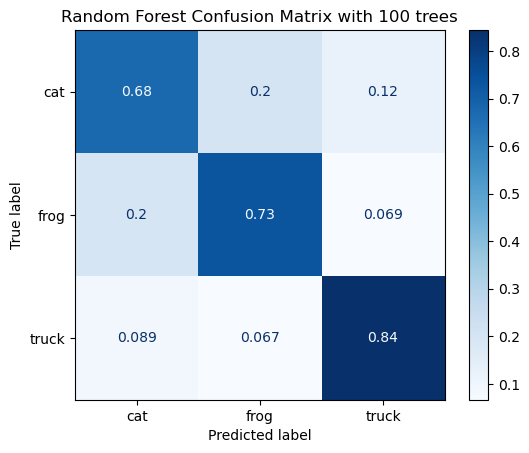

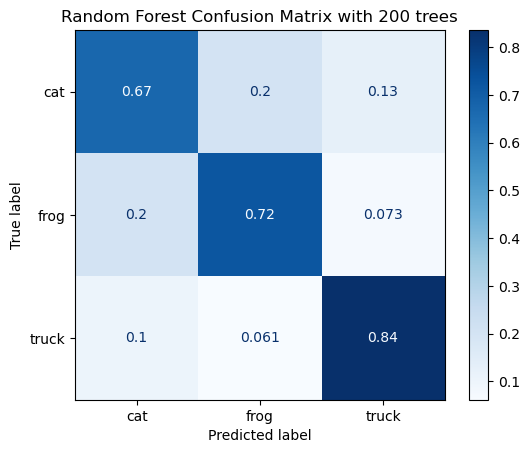

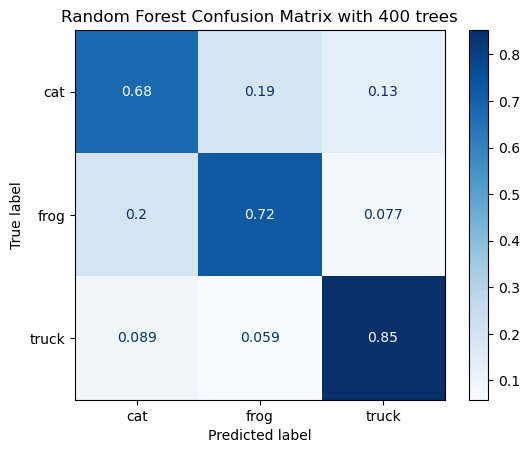

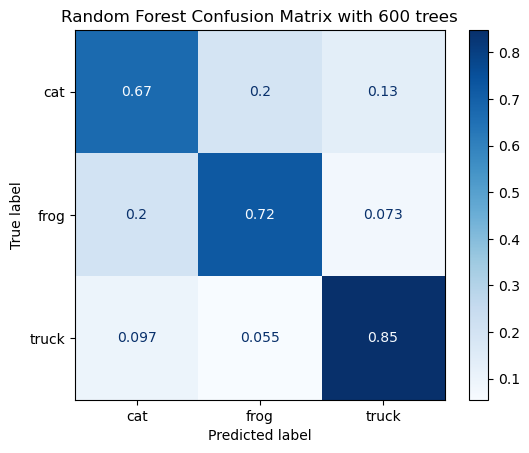

In [ ]:
# Printing accuracies
for accuracy in accuracies:
    print(f"Random Forest Test Accuracy with {accuracy} trees: {accuracies[accuracy]:.4f}")

# Displaying confusion matrices for each n_estimator value
for conf_matrix in confusion_matrices:
    ConfusionMatrixDisplay(confusion_matrices[conf_matrix], display_labels=list(class_names.values())).plot(cmap=plt.cm.Blues)
    plt.title(f"Random Forest Confusion Matrix with {conf_matrix} trees")
    plt.show()

## Q10 Measure importance of RGB coloring in accuracy

In [85]:

# CIFAR-10 is flattened as: [R(1024), G(1024), B(1024)]
R_train = X_train[:, :1024]
G_train = X_train[:, 1024:2048]
B_train = X_train[:, 2048:]

RF_GB = forests['100'].fit(np.hstack((G_train, B_train)), Y_train) # No red channel
RF_RB = forests['100'].fit(np.hstack((R_train, B_train)), Y_train) # No green channel
RF_BG = forests['100'].fit(np.hstack((R_train, G_train)), Y_train) # No blue channel


In [ ]:
# Identifying columns corresponding to each color channel in the test set
R_test = X_test[:, :1024]
G_test = X_test[:, 1024:2048]
B_test = X_test[:, 2048:]

# Predicting with each model that excludes one color channel and calculating their accuracies
GB_pred = RF_GB.predict(np.hstack((G_test, B_test))) # No red channel
RB_pred = RF_RB.predict(np.hstack((R_test, B_test))) # No green channel
BG_pred = RF_BG.predict(np.hstack((R_test, G_test))) # No blue channel

# Calculating accuracies for each model and comparing them to the accuracy of the full model with all channels
GB_acc = accuracy_score(Y_test, GB_pred)
RB_acc = accuracy_score(Y_test, RB_pred)
BG_acc = accuracy_score(Y_test, BG_pred)

print(f"Accuracy without Red channel: {GB_acc:.4f}")
print(f"Accuracy without Green channel: {RB_acc:.4f}")
print(f"Accuracy without Blue channel: {BG_acc:.4f}")

red_importance = accuracies['100'] - GB_acc
green_importance = accuracies['100'] - RB_acc
blue_importance = accuracies['100'] - BG_acc

print(f"Red channel importance: {red_importance:.4f}")
print(f"Green channel importance: {green_importance:.4f}")
print(f"Blue channel importance: {blue_importance:.4f}")

Accuracy without Red channel: 0.7040
Accuracy without Green channel: 0.7071
Accuracy without Blue channel: 0.7093
Red channel importance: 0.0476
Green channel importance: 0.0444
Blue channel importance: 0.0422


## Q11. Compute the accuracies of each tree in $RF_{100}$

In [102]:

# Compute individual test-set accuracy for each tree in RF_100 (forests['100'])
tree_accuracies = []
forests['100'].fit(X_train, Y_train) # Ensure the model is fitted before accessing estimators

for tree in forests['100'].estimators_:
    raw_pred = np.asarray(tree.predict(X_test))

    # Handle both possibilities:
    # 1) tree outputs encoded class indices (0..n_classes-1)
    # 2) tree outputs original labels directly (e.g., 3,6,9)
    try:
        tree_pred = forests['100'].classes_[raw_pred.astype(int)]
    except Exception:
        tree_pred = raw_pred

    tree_acc = accuracy_score(Y_test, tree_pred)
    tree_accuracies.append(tree_acc)

# Sort accuracies in increasing order
sorted_accuracies = np.sort(tree_accuracies)


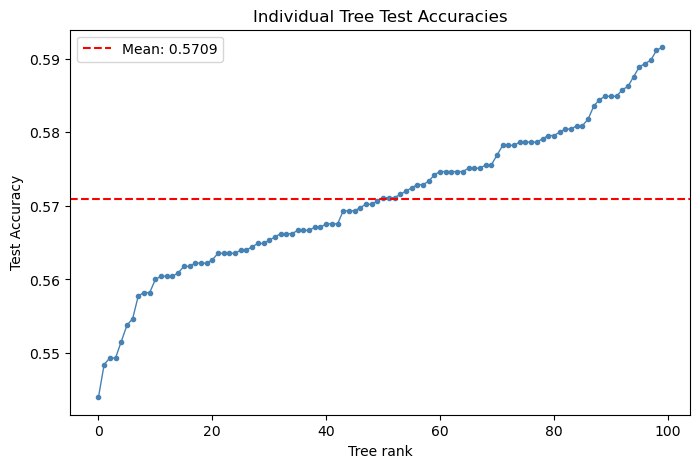

In [ ]:
# Sorted accuracies plot
fig = plt.figure(figsize=(8, 5))
plt.plot(sorted_accuracies, marker='o', markersize=3, linewidth=1, color='steelblue')
plt.title("Individual Tree Test Accuracies")
plt.xlabel("Tree rank")
plt.ylabel("Test Accuracy")
plt.axhline(y=np.mean(tree_accuracies), color='red', linestyle='--', label=f"Mean: {np.mean(tree_accuracies):.4f}")
plt.legend()


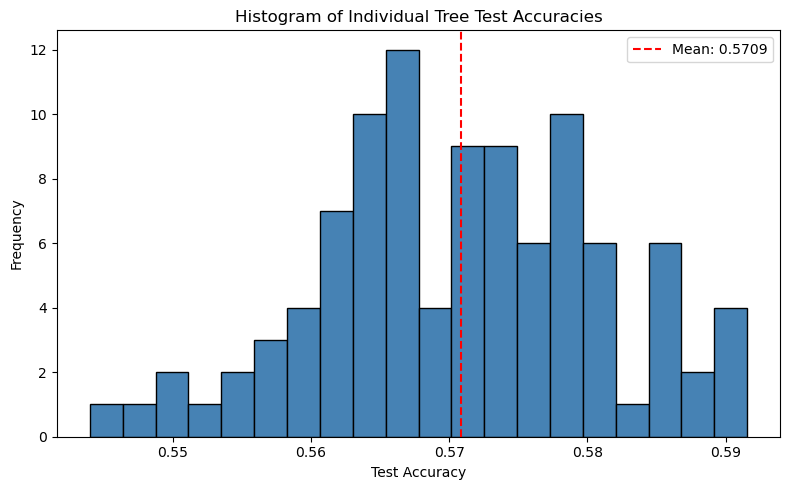

Min accuracy:  0.5440
Max accuracy:  0.5916
Mean accuracy: 0.5709
Std accuracy:  0.0101


In [ ]:

# Histogram of accuracies
fig = plt.figure(figsize=(8, 5))
plt.hist(tree_accuracies, bins=20, color='steelblue', edgecolor='black')
plt.title("Histogram of Individual Tree Test Accuracies")
plt.xlabel("Test Accuracy")
plt.ylabel("Frequency")
plt.axvline(x=np.mean(tree_accuracies), color='red', linestyle='--', label=f"Mean: {np.mean(tree_accuracies):.4f}")
plt.legend();plt.tight_layout();plt.show()

print(f"Min accuracy:  {sorted_accuracies[0]:.4f}")
print(f"Max accuracy:  {sorted_accuracies[-1]:.4f}")
print(f"Mean accuracy: {np.mean(tree_accuracies):.4f}")
print(f"Std accuracy:  {np.std(tree_accuracies):.4f}")


## Q12. Remove the 20% lowest-accuracy trees from RF* and evaluate the new ensemble

In [104]:
classes = forests['100'].classes_
trees = forests['100'].estimators_
N = len(trees)

# Helper: decode tree predictions if they are encoded as class indices
def decode_tree_prediction(raw_pred, classes):
    raw_pred = np.asarray(raw_pred)
    if np.issubdtype(raw_pred.dtype, np.integer):
        if raw_pred.min() >= 0 and raw_pred.max() < len(classes):
            return classes[raw_pred.astype(int)]
    return raw_pred

# Compute individual test accuracies for all N trees
individual_acc = []
for tree in trees:
    pred = decode_tree_prediction(tree.predict(X_test), classes)
    individual_acc.append(accuracy_score(Y_test, pred))

individual_acc = np.array(individual_acc)

# Eliminate M = 20% * N lowest-accuracy trees
M = int(np.floor(0.2 * N))
sorted_idx = np.argsort(individual_acc)  # ascending
kept_idx = sorted_idx[M:]                # keep top 80%
kept_trees = [trees[i] for i in kept_idx]


# Compare test accuracies: full RF* vs pruned RF (80% trees)
RF100_acc = accuracy_score(Y_test, forests['100'].predict(X_test))
forests['100'].estimators_ = kept_trees  # Update the forest to only use the kept trees
pruned_pred = forests['100'].predict(X_test)
pruned_test_acc = accuracy_score(Y_test, pruned_pred)

print(f"Total trees (N): {N}")
print(f"Removed lowest trees (M = 20% of N): {M}")
print(f"Kept trees: {len(kept_trees)}")
print(f"RF100 test accuracy (all {N} trees): {RF100_acc:.4f}")
print(f"Pruned RF test accuracy (top {len(kept_trees)} trees): {pruned_test_acc:.4f}")
print(f"Accuracy change (pruned - RF*): {pruned_test_acc - RF100_acc:+.4f}")

Total trees (N): 100
Removed lowest trees (M = 20% of N): 20
Kept trees: 80
RF100 test accuracy (all 100 trees): 0.7516
Pruned RF test accuracy (top 80 trees): 0.7498
Accuracy change (pruned - RF*): -0.0018
